In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import scipy.stats
import mdtraj as md
from typing import Dict, Tuple
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def calc_ccc(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mx = np.mean(x)
    my = np.mean(y)
    vx = np.var(x, ddof=0)
    vy = np.var(y, ddof=0)
    sxy = np.cov(x, y, ddof=0)[0, 1]

    return 2 * sxy / (vx + vy + (mx - my) ** 2)

def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

outpath='./HDX_stats_plots/'


In [2]:

proteins = [['alpha3D','Barnase', 'BarstarK60', 'betalactamasePSE4', 'BPTI', 'Calmodulin', 'CI2', 'DAXX', 'FKBP12', 'GB3'
            , 'HIVintegrase', 'HP36', 'Im7', 'Jarastatin', 'lDHFR','Lysozyme', 'PeroxiredoxinQ',  'SAMP1', 'Staph_nuclease_P117G_H124L', 'T4_lysozyme',  'Ubiquitin'],
            ['alpha3D', 'Barnase', 'betalactamasePSE4', 'CI2', 'FKBP12', 'GB3', 'HIVintegrase', 'HP36', 'Jarastatin', 'Lysozyme', 'PeroxiredoxinQ', 'Ubiquitin'],
            ['ACP', 'GB3', 'HP36', 'Jarastatin', 'lDHFR', 'Lysozyme', 'SAMP1', 'Ubiquitin'],
            ['GB3', 'Lysozyme', 'Ubiquitin'],
            ['BPTI', 'GB3', 'Ubiquitin']]

flat = [p for sub in proteins for p in sub]
proteins = sorted(set(flat))
print(len(proteins))
proteins




22


['ACP',
 'BPTI',
 'Barnase',
 'BarstarK60',
 'CI2',
 'Calmodulin',
 'DAXX',
 'FKBP12',
 'GB3',
 'HIVintegrase',
 'HP36',
 'Im7',
 'Jarastatin',
 'Lysozyme',
 'PeroxiredoxinQ',
 'SAMP1',
 'Staph_nuclease_P117G_H124L',
 'T4_lysozyme',
 'Ubiquitin',
 'alpha3D',
 'betalactamasePSE4',
 'lDHFR']

In [3]:
# check fraction of experimental residues that have open state sampling for these
for protein in proteins:
    nexp = len(list(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['Model_residue']))
    nopen = np.loadtxt(f"../../MD_DATA/{protein}/rewM14/log_lambda_rew_lnPF.txt").shape[0]
    fraction = nopen/nexp
    print(f'{protein}: {fraction:.2f}')

ACP: 0.71
BPTI: 0.79
Barnase: 0.71
BarstarK60: 0.54
CI2: 0.95
Calmodulin: 1.00
DAXX: 0.28
FKBP12: 1.00
GB3: 0.75
HIVintegrase: 0.94
HP36: 0.93
Im7: 0.54
Jarastatin: 1.00
Lysozyme: 0.63
PeroxiredoxinQ: 0.78
SAMP1: 0.88
Staph_nuclease_P117G_H124L: 0.78
T4_lysozyme: 0.54
Ubiquitin: 0.80
alpha3D: 0.98
betalactamasePSE4: 0.57
lDHFR: 0.76


Total unique proteins: 22


/tmp/ipykernel_1958879/1507343648.py:60: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  exp_residues = np.loadtxt(f"../../MD_DATA/{protein}/{model}/exp_residues.txt", dtype=int)
/tmp/ipykernel_1958879/1507343648.py:60: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floa

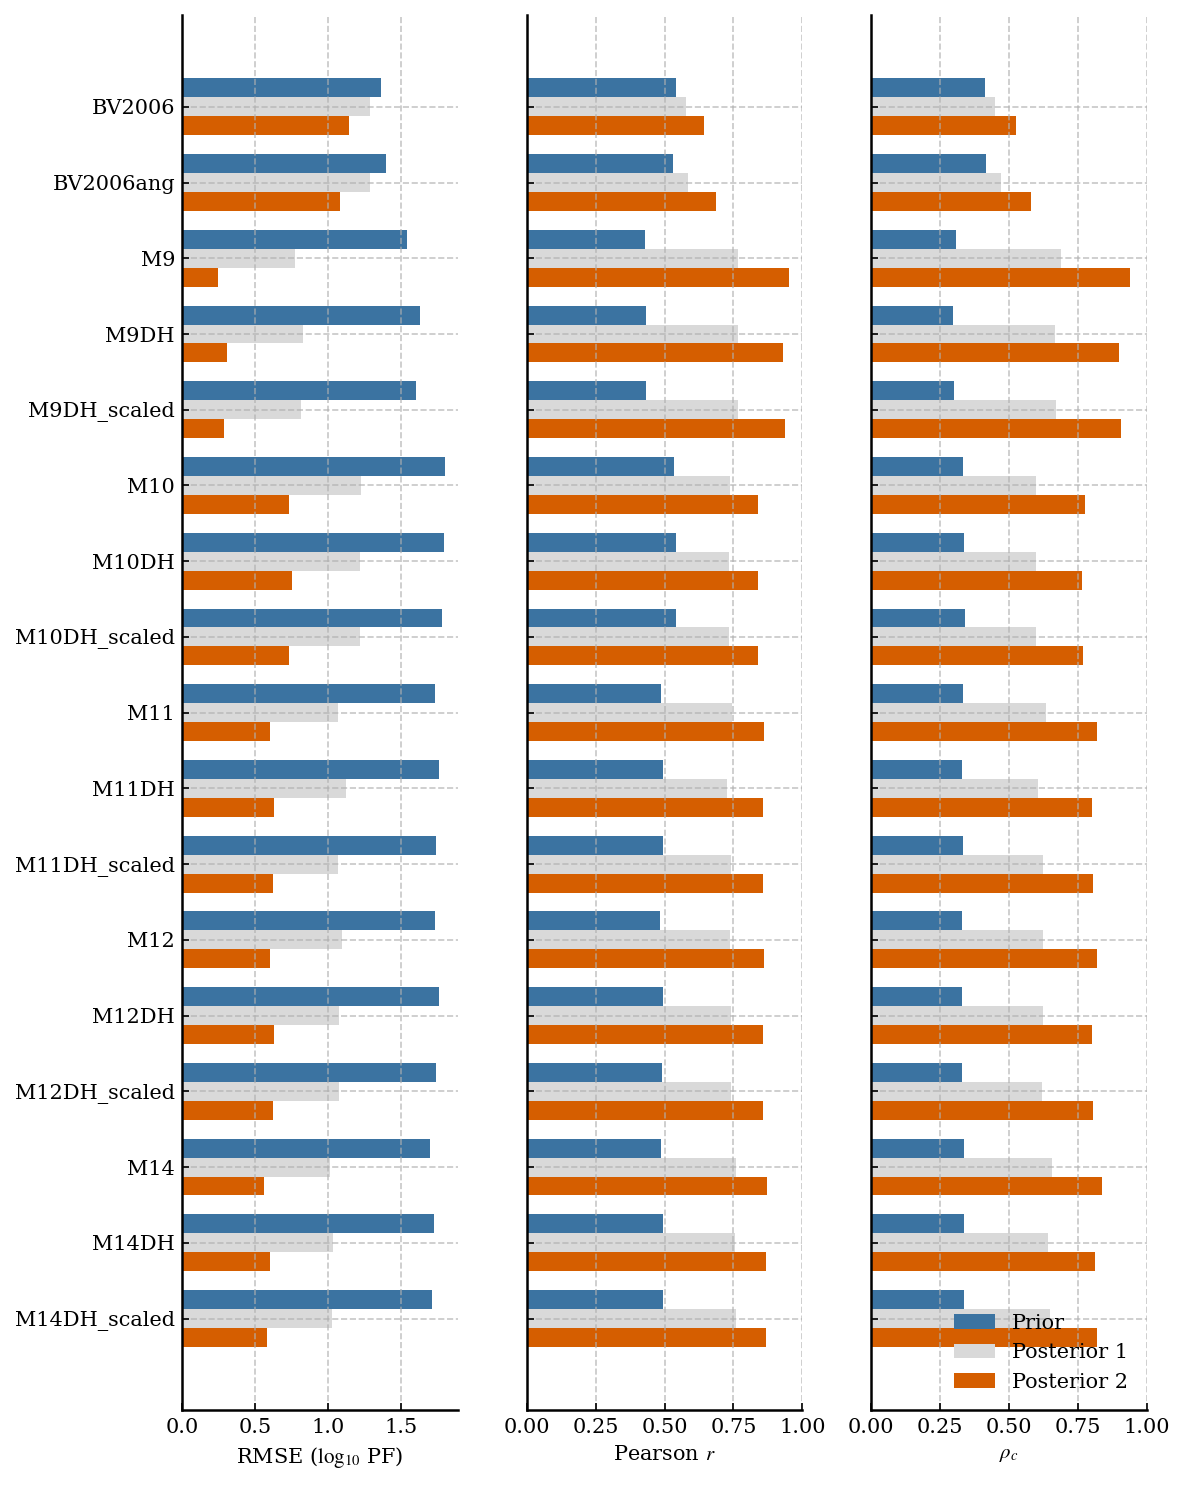

In [4]:
# --------------------------------------------------
# Models and labels
# --------------------------------------------------
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

labels = [model[3:] for model in models]
proteins_list = [['alpha3D','Barnase', 'BarstarK60', 'betalactamasePSE4', 'BPTI', 'Calmodulin', 'CI2', 'DAXX', 'FKBP12', 'GB3'
            , 'HIVintegrase', 'HP36', 'Im7', 'Jarastatin', 'lDHFR','Lysozyme', 'PeroxiredoxinQ',  'SAMP1', 'Staph_nuclease_P117G_H124L', 'T4_lysozyme',  'Ubiquitin'],
            ['alpha3D', 'Barnase', 'betalactamasePSE4', 'CI2', 'FKBP12', 'GB3', 'HIVintegrase', 'HP36', 'Jarastatin', 'Lysozyme', 'PeroxiredoxinQ', 'Ubiquitin'],
            ['ACP', 'GB3', 'HP36', 'Jarastatin', 'lDHFR', 'Lysozyme', 'SAMP1', 'Ubiquitin'],
            ['GB3', 'Lysozyme', 'Ubiquitin'],
            ['BPTI', 'GB3', 'Ubiquitin']]

# --------------------------------------------------
# Flatten and sort unique proteins
# --------------------------------------------------
flat = [protein for sublist in proteins_list for protein in sublist]
proteins = sorted(set(flat))

print("Total unique proteins:", len(proteins))

# --------------------------------------------------
# Storage for mean values
# --------------------------------------------------
rmse_prior_mean = []
rmse_post1_mean = []
rmse_post2_mean = []

r_prior_mean = []
r_post1_mean = []
r_post2_mean = []

ccc_prior_mean = []
ccc_post1_mean = []
ccc_post2_mean = []

# --------------------------------------------------
# Loop through models
# --------------------------------------------------
for model in models:

    rmse_prior_vals = []
    rmse_post1_vals = []
    rmse_post2_vals = []

    r_prior_vals = []
    r_post1_vals = []
    r_post2_vals = []

    ccc_prior_vals = []
    ccc_post1_vals = []
    ccc_post2_vals = []

    for protein in proteins:

        # Load PFs
        expPF = np.asarray(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['PF'], dtype=float)
        exp_residues = np.loadtxt(f"../../MD_DATA/{protein}/{model}/exp_residues.txt", dtype=int)
        all_exp_residues = np.array(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['Model_residue'])
        idxs = np.array([list(all_exp_residues).index(res) for res in exp_residues])
        expPF = expPF[idxs]
        PFprior = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/prior_lnPF.txt"))
        if 'BV' in model:
            PFpost1 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF_elbow.txt"))
            PFpost2 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF.txt"))
        else:
            PFpost1 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF_elbow.txt"))  
            PFpost2 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF.txt"))

        # Convert to log10 PF
        exp_log = np.log10(expPF)
        prior_log = np.log10(PFprior)
        post1_log = np.log10(PFpost1)
        post2_log = np.log10(PFpost2)

        # Calculate statistics
        rmse_prior_vals.append(RMSE(exp_log, prior_log))
        rmse_post1_vals.append(RMSE(exp_log, post1_log))
        rmse_post2_vals.append(RMSE(exp_log, post2_log))

        r_prior_vals.append(scipy.stats.pearsonr(exp_log, prior_log)[0])
        r_post1_vals.append(scipy.stats.pearsonr(exp_log, post1_log)[0])
        r_post2_vals.append(scipy.stats.pearsonr(exp_log, post2_log)[0])

        ccc_prior_vals.append(calc_ccc(exp_log, prior_log))
        ccc_post1_vals.append(calc_ccc(exp_log, post1_log))
        ccc_post2_vals.append(calc_ccc(exp_log, post2_log))

    # Store means across proteins
    rmse_prior_mean.append(np.mean(rmse_prior_vals))
    rmse_post1_mean.append(np.mean(rmse_post1_vals))
    rmse_post2_mean.append(np.mean(rmse_post2_vals))

    r_prior_mean.append(np.mean(r_prior_vals))
    r_post1_mean.append(np.mean(r_post1_vals))
    r_post2_mean.append(np.mean(r_post2_vals))

    ccc_prior_mean.append(np.mean(ccc_prior_vals))
    ccc_post1_mean.append(np.mean(ccc_post1_vals))
    ccc_post2_mean.append(np.mean(ccc_post2_vals))

# --------------------------------------------------
# Colours
# --------------------------------------------------
COLOR3 = "#3B73A1"  # prior
COLOR1 = "#D55E00"  # posterior 2
COLOR2 = "#D9D9D9"  # posterior 1

colors = {'Prior': COLOR3, 'Posterior 1': COLOR2, 'Posterior 2': COLOR1}

# --------------------------------------------------
# Organise plotting results
# --------------------------------------------------
results = {
    'RMSE': {'Prior': rmse_prior_mean, 'Posterior 1': rmse_post1_mean, 'Posterior 2': rmse_post2_mean},
    'Pearson r': {'Prior': r_prior_mean, 'Posterior 1': r_post1_mean, 'Posterior 2': r_post2_mean},
    'CCC': {'Prior': ccc_prior_mean, 'Posterior 1': ccc_post1_mean, 'Posterior 2': ccc_post2_mean}
}

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(8, 10), sharey=True)

stages = ['Prior', 'Posterior 1', 'Posterior 2']
stat_names = ['RMSE', 'Pearson r', 'CCC']
xlabels = [r'RMSE ($\log_{10}$ PF)', r'Pearson $r$', r'$\mathit{\rho_c}$']

n_models = len(models)
n_stages = len(stages)
bar_height = 0.25
y = np.arange(n_models)

for ax, stat_name, xlabel in zip(axes, stat_names, xlabels):

    for i, stage_name in enumerate(stages):
        offset = (i - (n_stages - 1) / 2) * bar_height
        ax.barh(y + offset, results[stat_name][stage_name], height=bar_height, label=stage_name, color=colors[stage_name])

    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)
    if stat_name == 'Pearson r' or stat_name == 'CCC':
        ax.set_xlim(0, 1)

axes[0].set_yticks(y)
axes[0].set_yticklabels(labels)
axes[0].invert_yaxis()

axes[-1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(outpath+'HDX_reweighting_models_summary_barplot_all.pdf', dpi=300, bbox_inches='tight')
plt.show()

Total unique proteins: 22


/tmp/ipykernel_919565/133177672.py:60: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  exp_residues = np.loadtxt(f"../../MD_DATA/{protein}/{model}/exp_residues.txt", dtype=int)
/tmp/ipykernel_919565/133177672.py:60: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating

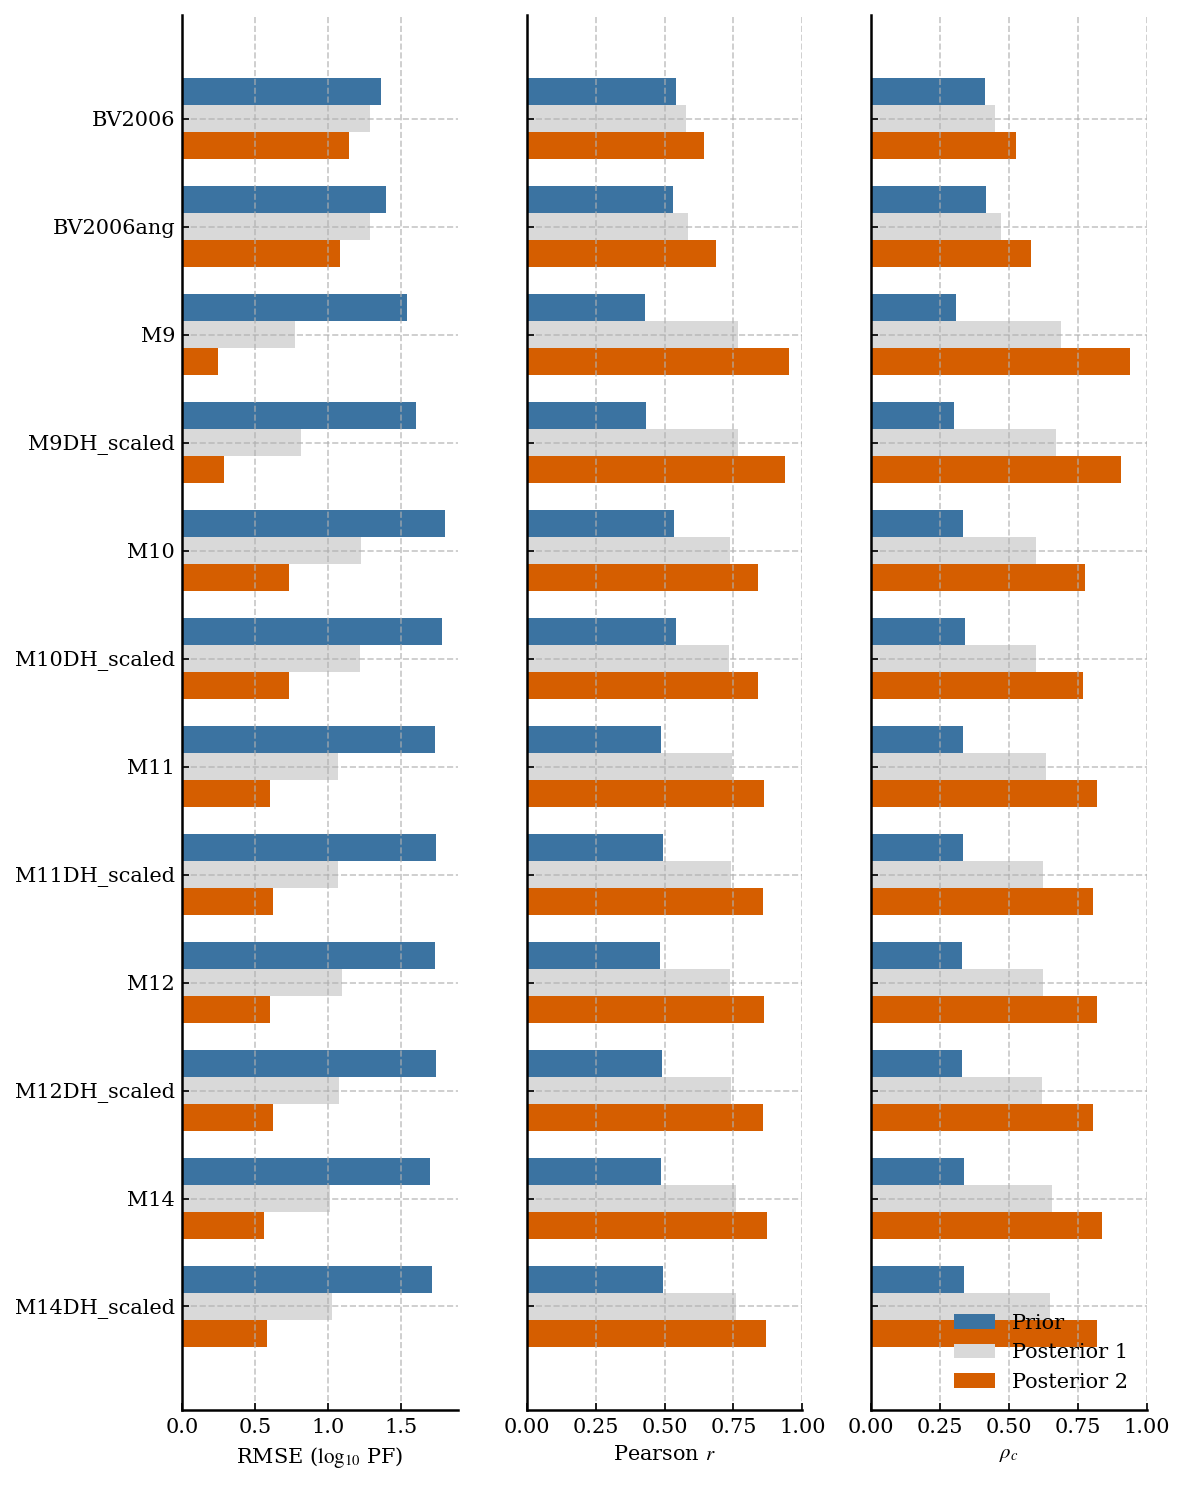

In [6]:
# --------------------------------------------------
# Models and labels
# --------------------------------------------------
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH_scaled', 'rewM11', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH_scaled', 'rewM14', 'rewM14DH_scaled']

labels = [model[3:] for model in models]
proteins_list = [['alpha3D','Barnase', 'BarstarK60', 'betalactamasePSE4', 'BPTI', 'Calmodulin', 'CI2', 'DAXX', 'FKBP12', 'GB3'
            , 'HIVintegrase', 'HP36', 'Im7', 'Jarastatin', 'lDHFR','Lysozyme', 'PeroxiredoxinQ',  'SAMP1', 'Staph_nuclease_P117G_H124L', 'T4_lysozyme',  'Ubiquitin'],
            ['alpha3D', 'Barnase', 'betalactamasePSE4', 'CI2', 'FKBP12', 'GB3', 'HIVintegrase', 'HP36', 'Jarastatin', 'Lysozyme', 'PeroxiredoxinQ', 'Ubiquitin'],
            ['ACP', 'GB3', 'HP36', 'Jarastatin', 'lDHFR', 'Lysozyme', 'SAMP1', 'Ubiquitin'],
            ['GB3', 'Lysozyme', 'Ubiquitin'],
            ['BPTI', 'GB3', 'Ubiquitin']]

# --------------------------------------------------
# Flatten and sort unique proteins
# --------------------------------------------------
flat = [protein for sublist in proteins_list for protein in sublist]
proteins = sorted(set(flat))

print("Total unique proteins:", len(proteins))

# --------------------------------------------------
# Storage for mean values
# --------------------------------------------------
rmse_prior_mean = []
rmse_post1_mean = []
rmse_post2_mean = []

r_prior_mean = []
r_post1_mean = []
r_post2_mean = []

ccc_prior_mean = []
ccc_post1_mean = []
ccc_post2_mean = []

# --------------------------------------------------
# Loop through models
# --------------------------------------------------
for model in models:

    rmse_prior_vals = []
    rmse_post1_vals = []
    rmse_post2_vals = []

    r_prior_vals = []
    r_post1_vals = []
    r_post2_vals = []

    ccc_prior_vals = []
    ccc_post1_vals = []
    ccc_post2_vals = []

    for protein in proteins:

        # Load PFs
        expPF = np.asarray(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['PF'], dtype=float)
        exp_residues = np.loadtxt(f"../../MD_DATA/{protein}/{model}/exp_residues.txt", dtype=int)
        all_exp_residues = np.array(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['Model_residue'])
        idxs = np.array([list(all_exp_residues).index(res) for res in exp_residues])
        expPF = expPF[idxs]
        PFprior = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/prior_lnPF.txt"))
        if 'BV' in model:
            PFpost1 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF_elbow.txt"))
            PFpost2 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF.txt"))
        else:
            PFpost1 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF_elbow.txt"))  
            PFpost2 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF.txt"))

        # Convert to log10 PF
        exp_log = np.log10(expPF)
        prior_log = np.log10(PFprior)
        post1_log = np.log10(PFpost1)
        post2_log = np.log10(PFpost2)

        # Calculate statistics
        rmse_prior_vals.append(RMSE(exp_log, prior_log))
        rmse_post1_vals.append(RMSE(exp_log, post1_log))
        rmse_post2_vals.append(RMSE(exp_log, post2_log))

        r_prior_vals.append(scipy.stats.pearsonr(exp_log, prior_log)[0])
        r_post1_vals.append(scipy.stats.pearsonr(exp_log, post1_log)[0])
        r_post2_vals.append(scipy.stats.pearsonr(exp_log, post2_log)[0])

        ccc_prior_vals.append(calc_ccc(exp_log, prior_log))
        ccc_post1_vals.append(calc_ccc(exp_log, post1_log))
        ccc_post2_vals.append(calc_ccc(exp_log, post2_log))

    # Store means across proteins
    rmse_prior_mean.append(np.mean(rmse_prior_vals))
    rmse_post1_mean.append(np.mean(rmse_post1_vals))
    rmse_post2_mean.append(np.mean(rmse_post2_vals))

    r_prior_mean.append(np.mean(r_prior_vals))
    r_post1_mean.append(np.mean(r_post1_vals))
    r_post2_mean.append(np.mean(r_post2_vals))

    ccc_prior_mean.append(np.mean(ccc_prior_vals))
    ccc_post1_mean.append(np.mean(ccc_post1_vals))
    ccc_post2_mean.append(np.mean(ccc_post2_vals))

# --------------------------------------------------
# Colours
# --------------------------------------------------
COLOR3 = "#3B73A1"  # prior
COLOR1 = "#D55E00"  # posterior 2
COLOR2 = "#D9D9D9"  # posterior 1

colors = {'Prior': COLOR3, 'Posterior 1': COLOR2, 'Posterior 2': COLOR1}

# --------------------------------------------------
# Organise plotting results
# --------------------------------------------------
results = {
    'RMSE': {'Prior': rmse_prior_mean, 'Posterior 1': rmse_post1_mean, 'Posterior 2': rmse_post2_mean},
    'Pearson r': {'Prior': r_prior_mean, 'Posterior 1': r_post1_mean, 'Posterior 2': r_post2_mean},
    'CCC': {'Prior': ccc_prior_mean, 'Posterior 1': ccc_post1_mean, 'Posterior 2': ccc_post2_mean}
}

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(8, 10), sharey=True)

stages = ['Prior', 'Posterior 1', 'Posterior 2']
stat_names = ['RMSE', 'Pearson r', 'CCC']
xlabels = [r'RMSE ($\log_{10}$ PF)', r'Pearson $r$', r'$\mathit{\rho_c}$']

n_models = len(models)
n_stages = len(stages)
bar_height = 0.25
y = np.arange(n_models)

for ax, stat_name, xlabel in zip(axes, stat_names, xlabels):

    for i, stage_name in enumerate(stages):
        offset = (i - (n_stages - 1) / 2) * bar_height
        ax.barh(y + offset, results[stat_name][stage_name], height=bar_height, label=stage_name, color=colors[stage_name])

    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)
    if stat_name == 'Pearson r' or stat_name == 'CCC':
        ax.set_xlim(0, 1)

axes[0].set_yticks(y)
axes[0].set_yticklabels(labels)
axes[0].invert_yaxis()

axes[-1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(outpath+'HDX_reweighting_models_summary_barplot.pdf', dpi=300, bbox_inches='tight')
plt.show()

Total unique proteins: 22


/tmp/ipykernel_1771556/2403253056.py:47: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  r_prior_vals.append(float(stats['rpearson prior']))
/tmp/ipykernel_1771556/2403253056.py:48: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  r_post_vals.append(float(stats['rpearson post']))
/tmp/ipykernel_1771556/2403253056.py:50: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rmse_prior_vals.append(float(stats['rmse prior']))
/tmp/ipykernel_1771556/2403253056.py:51: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rmse_post_vals.append(float(stats['rmse post']))
/tmp/ipykernel_1771556/2403253056.py:47: FutureWarning

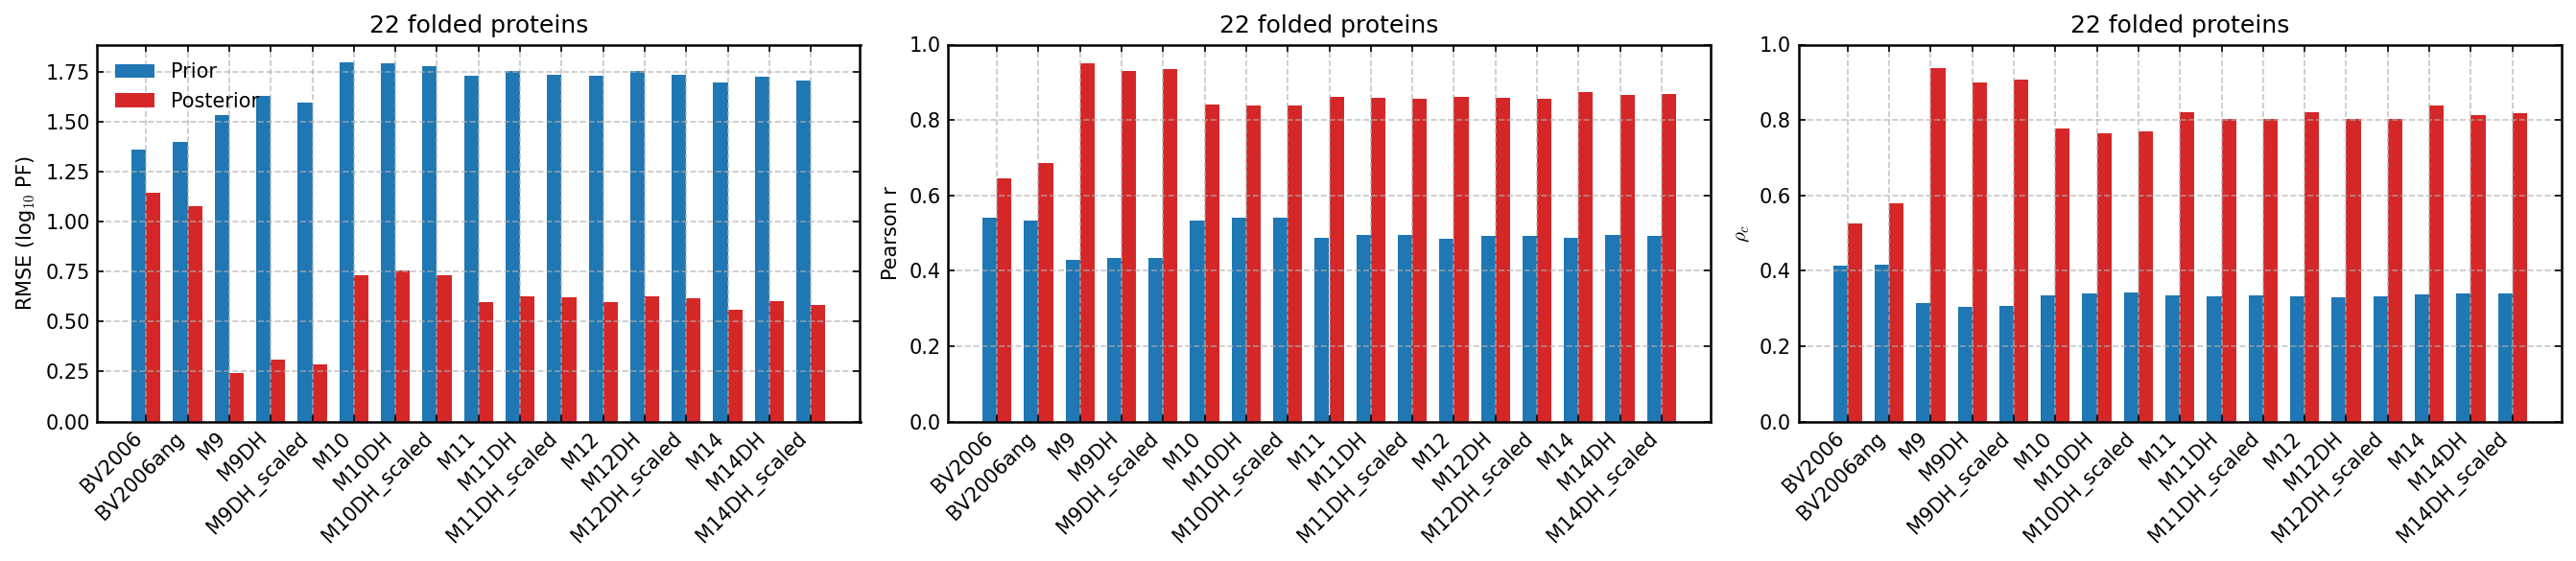

In [ ]:
# old version png

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

labels = [model[3:] for model in models]
proteins_list = [['alpha3D','Barnase', 'BarstarK60', 'betalactamasePSE4', 'BPTI', 'Calmodulin', 'CI2', 'DAXX', 'FKBP12', 'GB3'
            , 'HIVintegrase', 'HP36', 'Im7', 'Jarastatin', 'lDHFR','Lysozyme', 'PeroxiredoxinQ',  'SAMP1', 'Staph_nuclease_P117G_H124L', 'T4_lysozyme',  'Ubiquitin'],
            ['alpha3D', 'Barnase', 'betalactamasePSE4', 'CI2', 'FKBP12', 'GB3', 'HIVintegrase', 'HP36', 'Jarastatin', 'Lysozyme', 'PeroxiredoxinQ', 'Ubiquitin'],
            ['ACP', 'GB3', 'HP36', 'Jarastatin', 'lDHFR', 'Lysozyme', 'SAMP1', 'Ubiquitin'],
            ['GB3', 'Lysozyme', 'Ubiquitin'],
            ['BPTI', 'GB3', 'Ubiquitin']]

# ---- Flatten and sort unique proteins ----
flat = [p for sub in proteins_list for p in sub]
proteins = sorted(set(flat))
print("Total unique proteins:", len(proteins))

# ---- storage for means ----
rmse_prior_mean  = []
rmse_post_mean   = []
r_prior_mean     = []
r_post_mean      = []
ccc_prior_mean = []
ccc_post_mean = []

# ---- loop through models ----
for model in models:

    rmse_prior_vals = []
    rmse_post_vals  = []
    r_prior_vals    = []
    r_post_vals     = []
    ccc_prior_vals = []
    ccc_post_vals = []

    for protein in proteins:

        if not os.path.exists(f"../../MD_DATA/{protein}/{model}/stats_df.csv") and not os.path.exists(f"../../MD_DATA/{protein}/{model}/log_lambda_stats_df.csv"):
            print(f'No reweighting results for {protein}/{model}, skipping...')
            continue

        if model in ('rewBV2006', 'rewBV2006ang'):
            stats = pd.read_csv(f"../../MD_DATA/{protein}/{model}/stats_df.csv")
        else:
            stats = pd.read_csv(f"../../MD_DATA/{protein}/{model}/log_lambda_stats_df.csv")

        r_prior_vals.append(float(stats['rpearson prior']))
        r_post_vals.append(float(stats['rpearson post']))

        rmse_prior_vals.append(float(stats['rmse prior']))
        rmse_post_vals.append(float(stats['rmse post']))

        prior_PF = np.log10(np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/prior_lnPF.txt")))
        if model in ('rewBV2006', 'rewBV2006ang'):
            post_PF = np.log10(np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF.txt")))
        else:
            post_PF = np.log10(np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF.txt")))
        exp_PF = np.log10(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['PF'])
        all_exp_residues = np.array(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['Model_residue'])

        # check which residues had open state sampling and only keep those
        exp_residues = np.loadtxt(f"../../MD_DATA/{protein}/{model}/exp_residues.txt")
        keep = []
        for res in all_exp_residues:
            if res in exp_residues:
                keep.append(list(all_exp_residues).index(res))
        keep = np.array(keep)

        ccc_prior_vals.append(calc_ccc(prior_PF,exp_PF[keep]))
        ccc_post_vals.append(calc_ccc(post_PF,exp_PF[keep]))


    # store means
    rmse_prior_mean.append(np.mean(rmse_prior_vals))
    rmse_post_mean.append(np.mean(rmse_post_vals))
    r_prior_mean.append(np.mean(r_prior_vals))
    r_post_mean.append(np.mean(r_post_vals))
    ccc_prior_mean.append(np.mean(ccc_prior_vals))
    ccc_post_mean.append(np.mean(ccc_post_vals))

    

# ---- Plot: Three Panels (RMSE, Pearson r, CCC) ----

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
bar_width = 0.35
x = np.arange(len(models))

# ===== LEFT PANEL: RMSE =====
ax = axes[0]

ax.bar(x - bar_width/2, rmse_prior_mean, bar_width, label="Prior", color="tab:blue")
ax.bar(x + bar_width/2, rmse_post_mean,  bar_width, label="Posterior", color="tab:red")
ax.set_title(f"{len(proteins)} folded proteins")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel("RMSE (log$_{10}$ PF)")
ax.legend()

# ===== MIDDLE PANEL: Pearson r =====
ax = axes[1]

ax.bar(x - bar_width/2, r_prior_mean, bar_width, label="Prior", color="tab:blue")
ax.bar(x + bar_width/2, r_post_mean,  bar_width, label="Posterior", color="tab:red")
ax.set_title(f"{len(proteins)} folded proteins")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel("Pearson r")
ax.set_ylim(0, 1)

# ===== RIGHT PANEL: CCC =====
ax = axes[2]

ax.bar(x - bar_width/2, ccc_prior_mean, bar_width, label="Prior", color="tab:blue")
ax.bar(x + bar_width/2, ccc_post_mean,  bar_width, label="Posterior", color="tab:red")
ax.set_title(f"{len(proteins)} folded proteins")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel(r"$\rho_c$")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig("models_HDXstats_summary.png", dpi=200, bbox_inches="tight")

Total unique proteins: 38


/tmp/ipykernel_1771556/2549860587.py:47: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  r_prior_vals.append(float(stats['rpearson prior']))
/tmp/ipykernel_1771556/2549860587.py:48: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  r_post_vals.append(float(stats['rpearson post']))
/tmp/ipykernel_1771556/2549860587.py:50: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rmse_prior_vals.append(float(stats['rmse prior']))
/tmp/ipykernel_1771556/2549860587.py:51: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rmse_post_vals.append(float(stats['rmse post']))
/tmp/ipykernel_1771556/2549860587.py:47: FutureWarning

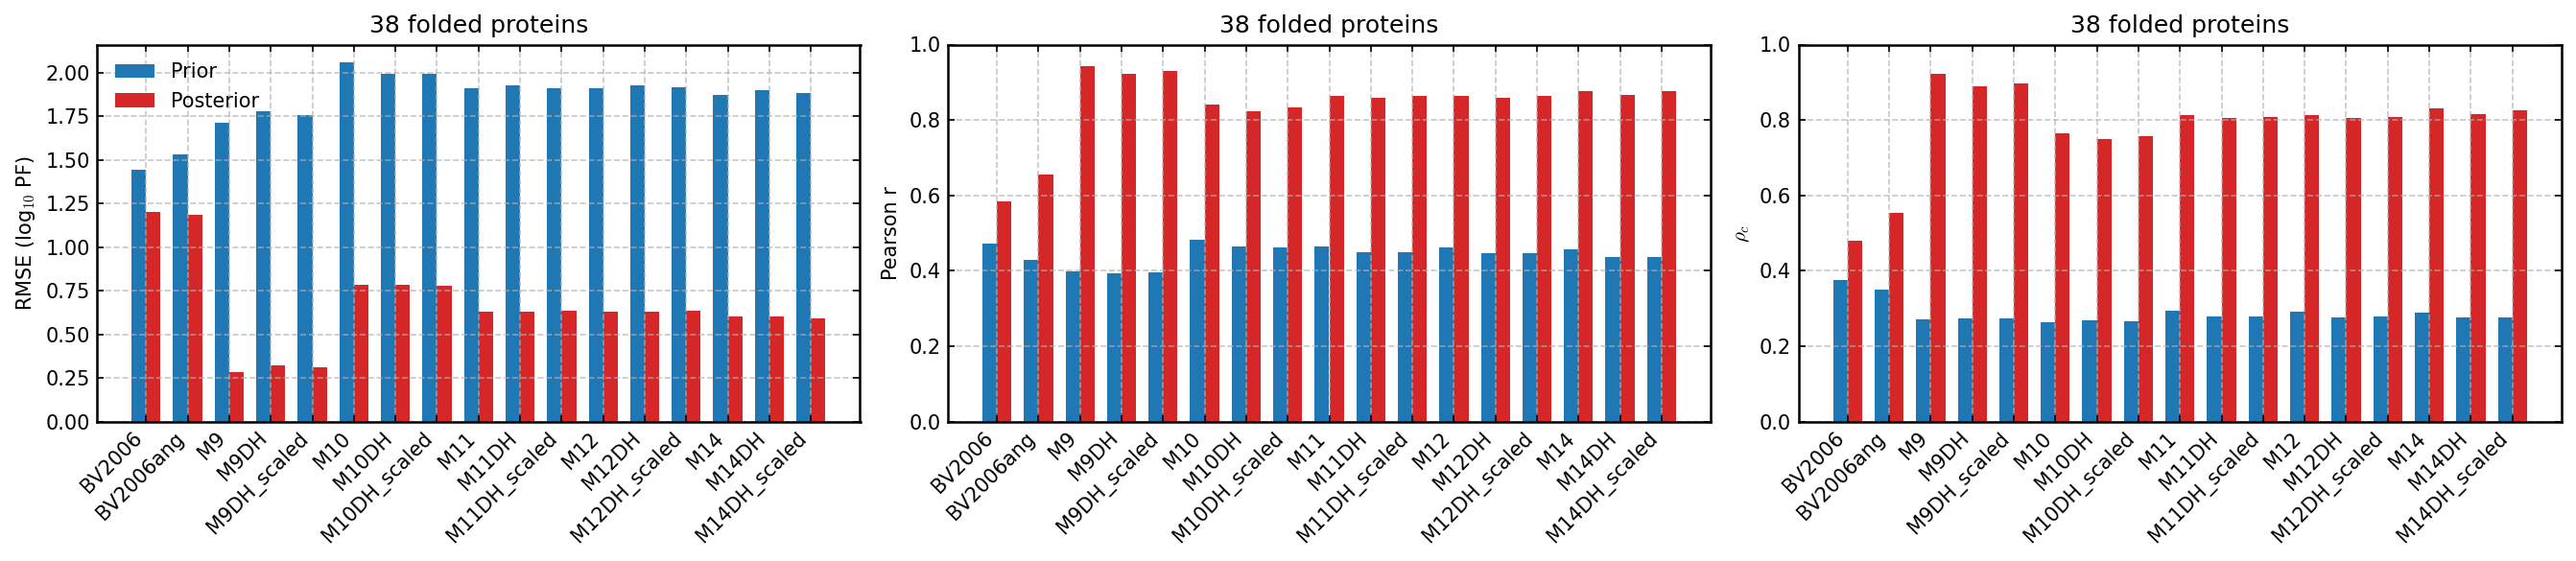

In [11]:

# now with all folded proteins from the dataset
proteins = ["ACBP", "ACP", "alpha3D", "At2g44940", "Barnase", "BarstarK60", "betalactamasePSE4", "BPTI", "Calbindin", 
            "CalcineurinB", "Calmodulin", "CI2", "ci2_I29A_I37H", "DAXX", "FKBP12", "fynSH3", "Galectin1", "GB3", "GCN4", "H14", 
            "hFGF1", "Hisactophilin1", "HIVintegrase", "HP36", "Im7", "Jarastatin", "Lactalbumin", "lDHFR", "Lysozyme", "NHP2L1", 
             "PeroxiredoxinQ", "RNaseA", "RNaseH", "RNaseT1", "SAMP1", "Staph_nuclease_P117G_H124L", "T4_lysozyme", "Ubiquitin"]



models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 'rewM10', 'rewM10DH', 'rewM10DH_scaled', 
          'rewM11', 'rewM11DH', 'rewM11DH_scaled', 'rewM12', 'rewM12DH', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH', 'rewM14DH_scaled']

labels = [model[3:] for model in models]

# ---- unique proteins ----
print("Total unique proteins:", len(proteins))

# ---- storage for means ----
rmse_prior_mean  = []
rmse_post_mean   = []
r_prior_mean     = []
r_post_mean      = []
ccc_prior_mean = []
ccc_post_mean = []

# ---- loop through models ----
for model in models:

    rmse_prior_vals = []
    rmse_post_vals  = []
    r_prior_vals    = []
    r_post_vals     = []
    ccc_prior_vals = []
    ccc_post_vals = []

    for protein in proteins:

        if not os.path.exists(f"../../MD_DATA/{protein}/{model}/stats_df.csv") and not os.path.exists(f"../../MD_DATA/{protein}/{model}/log_lambda_stats_df.csv"):
            print(f'No reweighting results for {protein}/{model}, skipping...')
            continue

        if model in ('rewBV2006', 'rewBV2006ang'):
            stats = pd.read_csv(f"../../MD_DATA/{protein}/{model}/stats_df.csv")
        else:
            stats = pd.read_csv(f"../../MD_DATA/{protein}/{model}/log_lambda_stats_df.csv")

        r_prior_vals.append(float(stats['rpearson prior']))
        r_post_vals.append(float(stats['rpearson post']))

        rmse_prior_vals.append(float(stats['rmse prior']))
        rmse_post_vals.append(float(stats['rmse post']))

        prior_PF = np.log10(np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/prior_lnPF.txt")))
        if model in ('rewBV2006', 'rewBV2006ang'):
            post_PF = np.log10(np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF.txt")))
        else:
            post_PF = np.log10(np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF.txt")))
        exp_PF = np.log10(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['PF'])
        all_exp_residues = np.array(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['Model_residue'])

        # check which residues had open state sampling and only keep those
        exp_residues = np.loadtxt(f"../../MD_DATA/{protein}/{model}/exp_residues.txt")
        keep = []
        for res in all_exp_residues:
            if res in exp_residues:
                keep.append(list(all_exp_residues).index(res))
        keep = np.array(keep)

        ccc_prior_vals.append(calc_ccc(prior_PF,exp_PF[keep]))
        ccc_post_vals.append(calc_ccc(post_PF,exp_PF[keep]))


    # store means
    rmse_prior_mean.append(np.mean(rmse_prior_vals))
    rmse_post_mean.append(np.mean(rmse_post_vals))
    r_prior_mean.append(np.mean(r_prior_vals))
    r_post_mean.append(np.mean(r_post_vals))
    ccc_prior_mean.append(np.mean(ccc_prior_vals))
    ccc_post_mean.append(np.mean(ccc_post_vals))

    

# ---- Plot: Three Panels (RMSE, Pearson r, CCC) ----

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
bar_width = 0.35
x = np.arange(len(models))

# ===== LEFT PANEL: RMSE =====
ax = axes[0]

ax.bar(x - bar_width/2, rmse_prior_mean, bar_width, label="Prior", color="tab:blue")
ax.bar(x + bar_width/2, rmse_post_mean,  bar_width, label="Posterior", color="tab:red")
ax.set_title(f"{len(proteins)} folded proteins")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel("RMSE (log$_{10}$ PF)")
ax.legend()

# ===== MIDDLE PANEL: Pearson r =====
ax = axes[1]

ax.bar(x - bar_width/2, r_prior_mean, bar_width, label="Prior", color="tab:blue")
ax.bar(x + bar_width/2, r_post_mean,  bar_width, label="Posterior", color="tab:red")
ax.set_title(f"{len(proteins)} folded proteins")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel("Pearson r")
ax.set_ylim(0, 1)

# ===== RIGHT PANEL: CCC =====
ax = axes[2]

ax.bar(x - bar_width/2, ccc_prior_mean, bar_width, label="Prior", color="tab:blue")
ax.bar(x + bar_width/2, ccc_post_mean,  bar_width, label="Posterior", color="tab:red")
ax.set_title(f"{len(proteins)} folded proteins")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel(r"$\rho_c$")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig("models_HDXstats_summary_allproteins.png", dpi=200, bbox_inches="tight")